# Embedding spread + SVM (from saved results)

Runs on the CSVs in `results/k5_clean/` that `LCA_Creativity.ipynb` already wrote. **No LLM runs**: it only reads
each model's word-embedding table from the Hugging Face cache (about 15 s), then trains small SVMs.

**Why a new metric?** In `LCA_Clustering.ipynb`, the LCA curves separated factual from creative only because
verbs sit lower in WordNet than nouns (and creative texts have more verbs). With that removed, the split
disappeared. WordNet may simply be the wrong ruler: it puts related science words (*crust, mantle, continent*)
on distant branches.

**The new ruler: embedding spread.** At each measured word we already saved the model's top-k guesses
(`candidates`). Instead of their WordNet LCA, measure how far apart they are in the model's own **word
embeddings** (the vectors the model uses to represent words):
- each guess becomes a vector; the **cosine distance** between two vectors is 0 for the same meaning
  and about 1 for unrelated words;
- `emb_mean` = average distance over all pairs of guesses (how spread out the guesses are);
- `emb_max` = the largest pair distance (closest to the max-based LCA height).

Two embedding spaces are compared:
- **LLM embeddings**: each model's own input word vectors (already on disk with the models). Each model's
  guesses are measured in that model's space.
- **GloVe**: classic word vectors (300 dimensions, 400k words, trained on Wikipedia + news), built
  specifically to place words with similar meanings close together (`glove_mean` / `glove_max`).
  First run downloads ~485 MB into the Hugging Face cache.

**Then:** turn each text's curves into features, and test them with an **SVM classifier**.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("HF_HUB_OFFLINE", "1")  # use files already on disk (set to "0" once to download GloVe)
import sys
import warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lca_core.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from lca_core import (CURVE_FEATURE_NAMES, add_embedding_spread, add_glove_spread, curve_features,
                      embedding_distance, glove_distance, lca, load_results, load_token_embeddings, pos_normalize,
                      unslug, windows)

warnings.filterwarnings("ignore")
RESULTS = ROOT / "src" / "note_books" / "LCA-Yoav" / "results" / "k5_clean"
FIG_DIR = RESULTS / "svm"
FIG_DIR.mkdir(exist_ok=True)
COLORS = {"factual": "#2a6fdb", "creative": "#e0662f"}
NL = chr(10)


def save(fig, path, tries=3):
    # OneDrive sometimes refuses the first overwrite of a synced file (OSError 22): remove it and retry
    for i in range(tries):
        try:
            return fig.savefig(path, dpi=110, bbox_inches="tight")
        except OSError:
            if i == tries - 1:
                print(f"could not save {path.name}")
                return
            path.unlink(missing_ok=True)


def short(name):
    return (name.replace("factual_wiki_", "wiki:").replace("factual_gut_", "gut:").replace("creative_gut_", "gut:")
            .replace("creative_", ""))


def source(name):
    """Where a text comes from: wiki / gutenberg / harry potter / jokes."""
    if "_gut_" in name:
        return "gutenberg"
    if "_wiki_" in name:
        return "wikipedia"
    return "jokes" if "jokes" in name else "harry potter"


# ---- which texts to use ------------------------------------------------------------
# "original": the first 18 texts (8 Wikipedia, 8 Harry Potter, 2 joke books)
# "extended": without the short Harry Potter opening (261 words vs ~700), plus 8 Gutenberg texts
#             (4 factual: Einstein, Faraday, Darwin, Thomson; 4 creative: Alice, Sherlock Holmes, Oz, Grimm)
DATASET = "extended"
SHORT_TEXT = "creative_harry_potter"

data = load_results(RESULTS)
if DATASET == "original":
    data = {m: {t: df for t, df in per.items() if "_gut_" not in t} for m, per in data.items()}
else:
    data = {m: {t: df for t, df in per.items() if t != SHORT_TEXT} for m, per in data.items()}
FIG_DIR = FIG_DIR / DATASET
FIG_DIR.mkdir(exist_ok=True)
names = sorted(next(iter(data.values())))
print(f"DATASET = {DATASET}: {len(names)} texts per model")
print(pd.Series([f"{'factual' if n.startswith('factual') else 'creative'} / {source(n)}" for n in names]).value_counts())

DATASET = extended: 25 texts per model
factual / wikipedia        8
creative / harry potter    7
creative / gutenberg       4
factual / gutenberg        4
creative / jokes           2
Name: count, dtype: int64


## 1. Sanity check: does embedding distance behave sensibly?
The same pairs as the LCA sanity check, plus two topic pairs. Smaller = closer in meaning.
Each model has its own embeddings, so each gets its own column.

In [2]:
PAIRS = [("dog", "cat"), ("canine", "cat"), ("dog", "chair"), ("volcano", "lava"), ("volcano", "joke"),
         ("run", "walk"), ("run", "think")]
rows = []
for a, b in PAIRS:
    row = {"pair": f"{a} / {b}", "LCA height (WordNet)": lca([a, b], "v" if a == "run" else "n")[0]}
    for m in data:
        tok, E = load_token_embeddings(unslug(m))
        row[f"emb dist ({m.split('_')[-1]})"] = round(embedding_distance(a, b, tok, E), 3)
    row["GloVe dist"] = round(glove_distance(a, b), 3)
    rows.append(row)
pd.DataFrame(rows).set_index("pair")

,LCA height (WordNet),emb dist (pythia-410m),emb dist (gpt2-medium),emb dist (Qwen2.5-1.5B),GloVe dist
pair,,,,,
dog / cat,2,0.684,0.564,0.652,0.318
canine / cat,2,0.855,0.776,0.842,0.646
dog / chair,6,0.918,0.890,0.951,0.819
volcano / lava,7,0.691,0.546,0.665,0.356
volcano / joke,6,0.983,0.927,0.958,1.011
run / walk,2,0.812,0.726,0.791,0.525
run / think,3,0.924,0.797,0.862,0.627


## 2. Compute the embedding spread at every measured word
Adds `emb_mean` / `emb_max` (LLM embeddings) and `glove_mean` / `glove_max` (GloVe) to every result table, then a
**POS-corrected** copy of each metric (`lca_z`, `emb_z`, `glove_z`): every point's value compared with the average
for its part of speech (0 = typical noun or verb), so the noun/verb mix of a text no longer matters.

In [3]:
data = add_embedding_spread(data)
data = add_glove_spread(data)
data = pos_normalize(data, "lca_height", "lca_z")
data = pos_normalize(data, "emb_mean", "emb_z")
data = pos_normalize(data, "glove_mean", "glove_z")


def remove_rarity(data):
    """glove_r: GloVe spread with the effect of word rarity (and part of speech) removed.
    Per model and POS, fit glove_mean ~ glove_logrank with a straight line and keep what the line can't explain
    (in SD units). 0 = as spread out as expected for guesses this rare."""
    out = {}
    for m, per in data.items():
        allp = pd.concat(per.values())
        fits = {}
        for pos, g in allp.groupby("pos"):
            slope, intercept = np.polyfit(g["glove_logrank"], g["glove_mean"], 1)
            resid_sd = (g["glove_mean"] - (slope * g["glove_logrank"] + intercept)).std()
            fits[pos] = (slope, intercept, resid_sd)
        out[m] = {}
        for t, df in per.items():
            s, i, sd = (df["pos"].map(lambda p: fits[p][k]) for k in range(3))
            out[m][t] = df.assign(glove_r=(df["glove_mean"] - (s * df["glove_logrank"] + i)) / sd)
    return out


data = remove_rarity(data)

points = pd.concat([df.assign(model=m, text=t, kind="factual" if t.startswith("factual") else "creative")
                    for m, per in data.items() for t, df in per.items()], ignore_index=True)
print(len(points), "measured points")
data["gpt2-medium"]["creative_hp1"][["word", "pos", "candidates", "lca_height", "emb_mean", "glove_mean"]].head(8)

14632 measured points


,word,pos,candidates,lca_height,emb_mean,glove_mean
0,end,n,story moment official article time,5,0.782851,0.699700
1,hear,v,kill see take tell use,2,0.698771,0.557451
2,running,n,sound point state,5,0.817914,0.759092
3,shouts,n,house room door office bedroom,4,0.716670,0.532904
4,move,n,god shit fuck crap hell,7,0.623025,0.628813
5,snarled,v,whisper yell scream cry call,5,0.731321,0.618080
6,grabbed,v,grab turn run reach slam,2,0.819137,0.687410
7,wand,n,arm hand wrist wand shoulder,7,0.743049,0.618963


## 3. Is it a different measure from LCA, and does it have the verb problem?
- **Correlation with LCA** (Spearman: 1 = same ranking, 0 = unrelated). If it's close to 1, the embedding
  metric would just repeat the LCA result.
- **Noun vs verb gap**, in standard deviations of each metric. LCA's gap is what caused the verb problem.

Spearman correlation between the metrics (every measured point):


,LCA height,LLM-embedding spread,GloVe spread
LCA height,1.00,0.29,0.40
LLM-embedding spread,0.29,1.00,0.64
GloVe spread,0.40,0.64,1.00


,noun mean,verb mean,gap in SDs
LCA height,6.469,3.088,1.478
LLM-embedding spread,0.857,0.830,0.391
GloVe spread,0.719,0.635,0.725


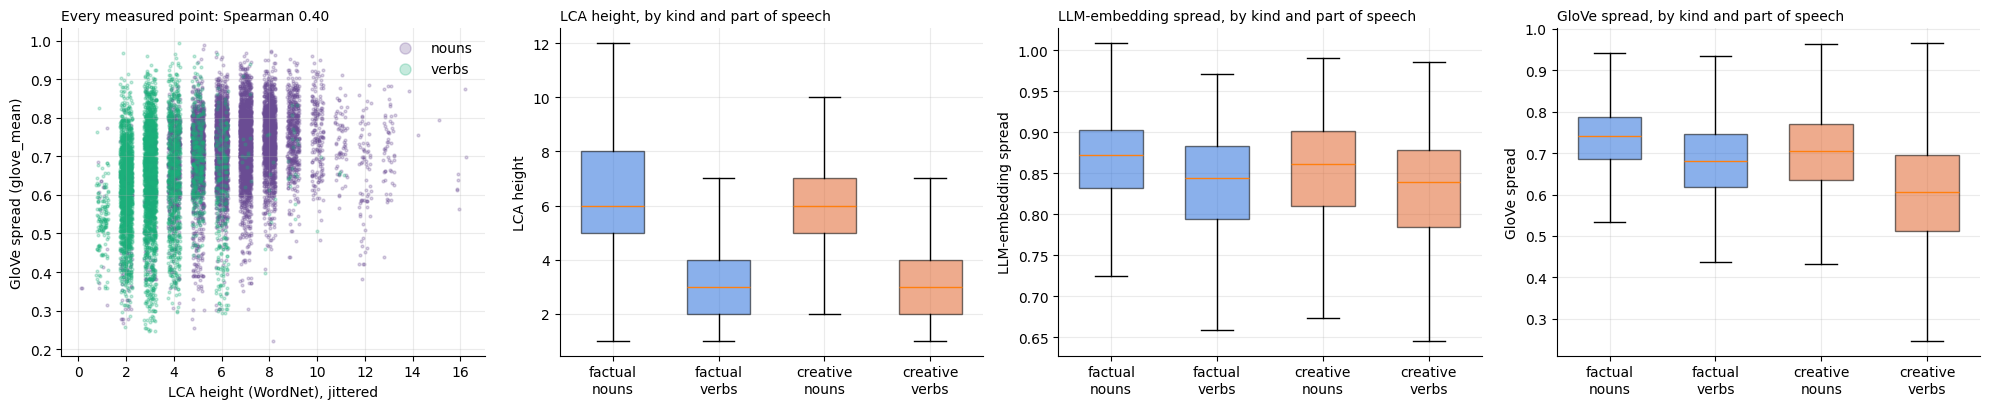

In [4]:
METRICS = {"lca_height": "LCA height", "emb_mean": "LLM-embedding spread", "glove_mean": "GloVe spread"}
print("Spearman correlation between the metrics (every measured point):")
display(points[list(METRICS)].rename(columns=METRICS).corr(method="spearman").round(2))

gap = {}
for col, title in METRICS.items():
    by = points.groupby("pos")[col].mean()
    gap[title] = {"noun mean": by["n"], "verb mean": by["v"], "gap in SDs": (by["n"] - by["v"]) / points[col].std()}
display(pd.DataFrame(gap).T.round(3))

rho = spearmanr(points["lca_height"], points["glove_mean"]).statistic
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
ax = axes[0]
for pos, color, label in [("n", "#6a4c93", "nouns"), ("v", "#1baf7a", "verbs")]:
    sub = points[points.pos == pos]
    ax.scatter(sub["lca_height"] + np.random.uniform(-0.25, 0.25, len(sub)), sub["glove_mean"], s=4, alpha=0.25,
               color=color, label=label)
ax.set_xlabel("LCA height (WordNet), jittered")
ax.set_ylabel("GloVe spread (glove_mean)")
ax.set_title(f"Every measured point: Spearman {rho:.2f}", loc="left", fontsize=10)
ax.legend(frameon=False, markerscale=4)
for ax, (col, title) in zip(axes[1:], METRICS.items()):
    parts = [points[(points.kind == k) & (points.pos == p)][col] for k in ("factual", "creative") for p in ("n", "v")]
    bp = ax.boxplot(parts, tick_labels=["factual" + NL + "nouns", "factual" + NL + "verbs",
                                        "creative" + NL + "nouns", "creative" + NL + "verbs"],
                    patch_artist=True, showfliers=False, widths=0.6)
    for patch, k in zip(bp["boxes"], ["factual"] * 2 + ["creative"] * 2):
        patch.set_facecolor(COLORS[k])
        patch.set_alpha(0.55)
    ax.set_title(f"{title}, by kind and part of speech", loc="left", fontsize=10)
    ax.set_ylabel(title)
for ax in axes:
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
save(fig, FIG_DIR / "1_lca_vs_embedding.png")
plt.show()

## 4. Spread of the embedding curve, per text
One box per text (all 3 models pooled), coloured by true kind. The hypothesis predicts **wider** boxes
(more converging/diverging) for creative texts.

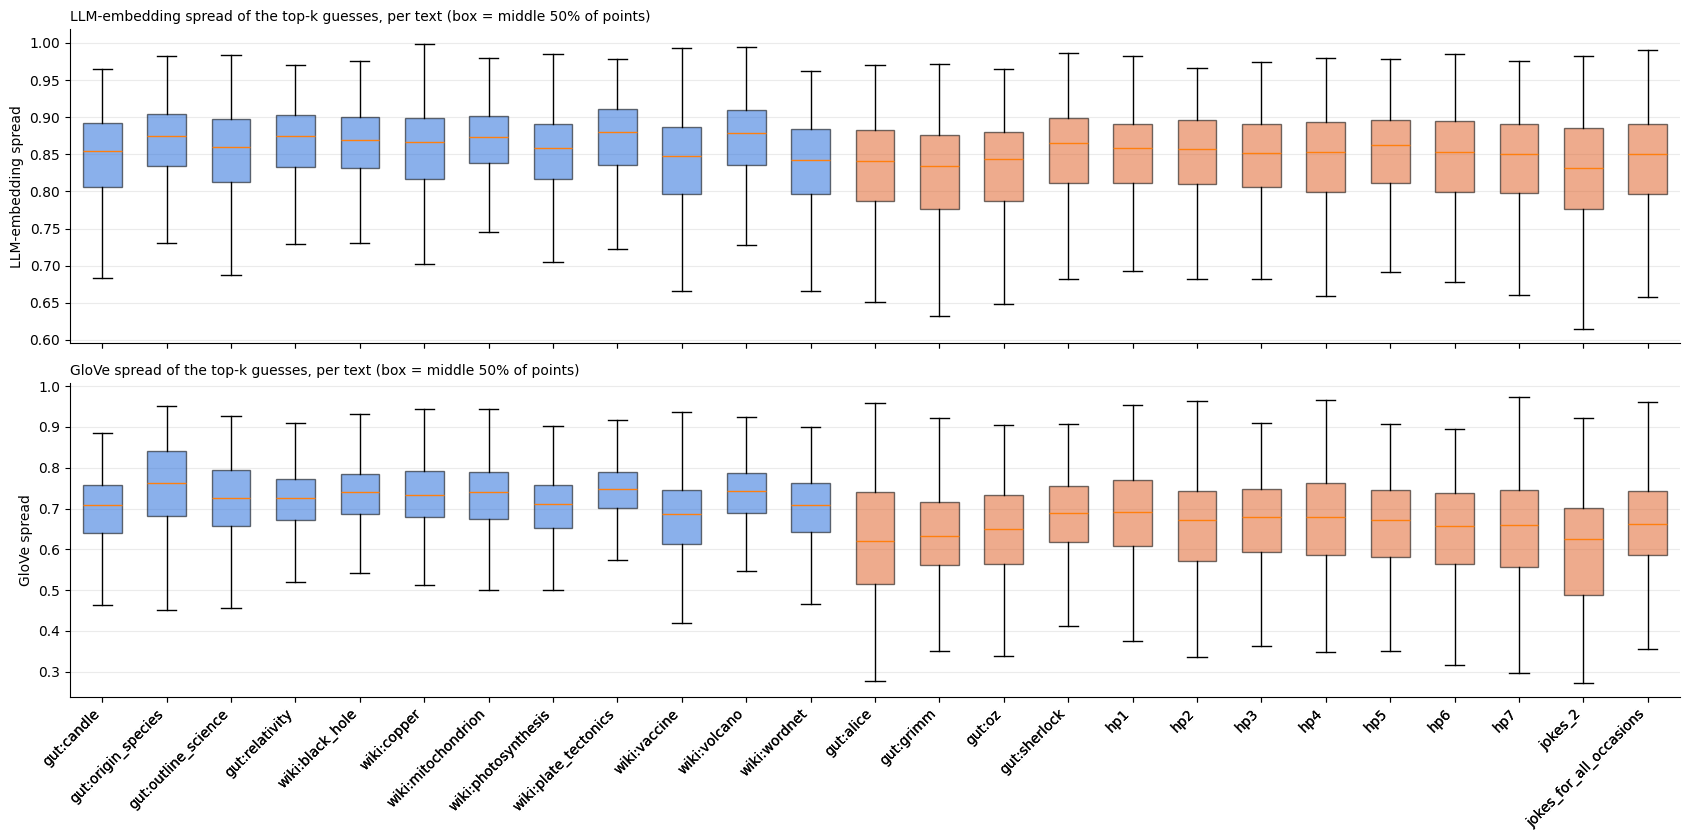

emb_mean        glove_mean       
             mean    std       mean    std
kind                                      
creative    0.837  0.074      0.649  0.129
factual     0.855  0.061      0.719  0.089

In [5]:
order = sorted(points["text"].unique(), key=lambda t: (not t.startswith("factual"), t))
fig, axes = plt.subplots(2, 1, figsize=(17, 8.5), sharex=True)
for ax, col in zip(axes, ["emb_mean", "glove_mean"]):
    bp = ax.boxplot([points[points.text == t][col] for t in order], tick_labels=[short(t) for t in order],
                    patch_artist=True, showfliers=False, widths=0.6)
    for patch, t in zip(bp["boxes"], order):
        patch.set_facecolor(COLORS["factual" if t.startswith("factual") else "creative"])
        patch.set_alpha(0.55)
    ax.set_ylabel(METRICS[col])
    ax.set_title(f"{METRICS[col]} of the top-k guesses, per text (box = middle 50% of points)", loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
save(fig, FIG_DIR / "2_embedding_per_text.png")
plt.show()

per_text = points.groupby(["text", "kind"])[["emb_mean", "glove_mean"]].agg(["mean", "std"])
per_text.groupby(level="kind").mean().round(3)

## 4b. Is GloVe just measuring how rare the guessed words are?
GloVe's word list is sorted from most to least common. Rare words have noisier vectors, so a set of rare words
can look "spread out" without being different in meaning. If factual guesses are rarer (science vocabulary), the
GloVe metric could be measuring **rarity** instead of meaning.

`glove_logrank` = average log position of the guesses in that list (higher = rarer). `glove_r` = GloVe spread with
rarity and part of speech removed (see `remove_rarity` in section 2).

In [6]:
print("Spearman GloVe spread vs rarity:", round(spearmanr(points["glove_mean"], points["glove_logrank"]).statistic, 2))
points.groupby(["kind", "pos"])[["glove_logrank", "glove_mean", "glove_r"]].mean().round(3)

Spearman GloVe spread vs rarity: 0.48


glove_logrank  glove_mean  glove_r
kind     pos                                    
creative n            7.483       0.694   -0.167
         v            7.203       0.603   -0.165
factual  n            7.937       0.733    0.097
         v            7.579       0.681    0.237

## 5. Features
Each curve becomes the same shape numbers as in the clustering notebook: average level, variance, average jump,
largest jump, up/down direction changes (plus share of high points for raw LCA). Feature sets:

| set | what it uses |
|---|---|
| LCA, raw | WordNet LCA height (has the verb problem) |
| LCA, POS-corrected | LCA height compared with the typical value for its part of speech |
| LLM emb | LLM-embedding spread (`emb_mean`) |
| LLM emb, POS-corrected | the same, compared with its part of speech |
| GloVe | GloVe spread (`glove_mean`) |
| GloVe, POS-corrected | the same, compared with its part of speech |
| Word rarity only | how rare the guesses are (`glove_logrank`): not about meaning, a check for GloVe |
| GloVe, rarity + POS-corrected | GloVe spread with rarity and part of speech removed (`glove_r`) |
| GloVe + LCA (POS-corr.) | both corrected metrics together |
| Confidence | P(real word) and probability of the top-k guesses: a baseline that isn't about meaning |
| GloVe (POS-corr.) + confidence | does GloVe add anything on top of confidence? |

In [7]:
SHAPE = [f for f in CURVE_FEATURE_NAMES if f != "share_ge_8"]


def curve_feats(df, col, prefix, high=False):
    vals = curve_features(df[col])
    return {f"{prefix}{n}": v for n, v in zip(CURVE_FEATURE_NAMES, vals) if high or n != "share_ge_8"}


def row_features(df):
    r = {}
    r.update(curve_feats(df, "lca_height", "lca_", high=True))
    r.update(curve_feats(df, "lca_z", "lcaz_"))
    r.update(curve_feats(df, "emb_mean", "emb_"))
    r.update(curve_feats(df, "emb_z", "embz_"))
    r.update(curve_feats(df, "glove_mean", "glove_"))
    r.update(curve_feats(df, "glove_z", "glovez_"))
    r.update(curve_feats(df, "glove_r", "glover_"))
    r.update(curve_feats(df, "glove_logrank", "rarity_"))
    r["emb_max_mean"] = df["emb_max"].mean()
    r["glove_max_mean"] = df["glove_max"].mean()
    r["conf_actual_word_prob"] = df["actual_word_prob"].mean()
    r["conf_cand_mass"] = df["cand_mass"].mean()
    return r


cols = lambda prefix: [f"{prefix}{n}" for n in SHAPE]
SETS = {
    "LCA, raw": [f"lca_{n}" for n in CURVE_FEATURE_NAMES],
    "LCA, POS-corrected": cols("lcaz_"),
    "LLM emb": cols("emb_") + ["emb_max_mean"],
    "LLM emb, POS-corrected": cols("embz_"),
    "GloVe": cols("glove_") + ["glove_max_mean"],
    "GloVe, POS-corrected": cols("glovez_"),
    "Word rarity only": cols("rarity_"),
    "GloVe, rarity + POS-corrected": cols("glover_"),
    "GloVe (rarity+POS) + LCA (POS)": cols("glover_") + cols("lcaz_"),
    "Confidence": ["conf_actual_word_prob", "conf_cand_mass"],
    "GloVe (rarity+POS) + confidence": cols("glover_") + ["conf_actual_word_prob", "conf_cand_mass"],
}

# text level: one row per text (features averaged over the 3 models)
per_model = pd.DataFrame([dict(model=m, text=t, **row_features(df)) for m, per in data.items() for t, df in per.items()])
texts = per_model.drop(columns="model").groupby("text", as_index=False).mean()
texts["kind"] = np.where(texts["text"].str.startswith("factual"), "factual", "creative")

# window level: 40-point windows, step 20, per model (like the SVM in LCA_Creativity.ipynb)
WIN, STEP = 40, 20
win_rows = []
for m, per in data.items():
    for t, df in per.items():
        for s, _ in windows(np.arange(len(df)), WIN, STEP):
            win_rows.append(dict(model=m, text=t, start=s, **row_features(df.iloc[s:s + WIN])))
wins = pd.DataFrame(win_rows)
wins["kind"] = np.where(wins["text"].str.startswith("factual"), "factual", "creative")
print(f"text level: {len(texts)} texts   window level: {len(wins)} windows from {wins.text.nunique()} texts")
N_TEXTS = len(texts)

text level: 25 texts   window level: 621 windows from 25 texts


### Which features differ between factual and creative?
Effect size (Cohen's d, creative minus factual) per text, for the main metrics. |d| > 0.8 is a large difference;
the sign says which kind is higher.

In [8]:
NICE = {"mean": "average level", "var": "variance", "mean_abs_jump": "average jump", "max_abs_jump": "largest jump",
        "direction_changes": "up/down direction changes"}
f, c = texts[texts.kind == "factual"], texts[texts.kind == "creative"]
d = lambda col: (c[col].mean() - f[col].mean()) / np.sqrt((c[col].var() + f[col].var()) / 2)
pd.DataFrame({title: {NICE[n]: d(f"{prefix}{n}") for n in SHAPE}
              for prefix, title in [("lcaz_", "LCA (POS-corr.)"), ("embz_", "LLM emb (POS-corr.)"),
                                    ("glovez_", "GloVe (POS-corr.)"), ("glover_", "GloVe (rarity+POS)"),
                                    ("rarity_", "word rarity")]}).round(2)

,LCA (POS-corr.),LLM emb (POS-corr.),GloVe (POS-corr.),GloVe (rarity+POS),word rarity
average level,-0.65,-1.05,-2.22,-1.62,-3.11
variance,0.08,1.34,2.15,1.09,1.12
average jump,0.37,1.56,2.46,1.71,1.48
largest jump,0.12,1.02,1.69,0.88,0.60
up/down direction changes,-0.04,0.32,0.24,0.50,0.18


## 6. SVM classifier
An **SVM** (support vector machine) is *given* the labels and learns a boundary that separates factual from
creative in feature space. Unlike clustering, it can ignore features that don't help.

How it's tested, so the score is honest:
- **Leave-one-text-out:** train on all texts but one, predict the left-out text, repeat for every text. The SVM is
  never graded on a text it trained on. At window level, all windows of the left-out text are held out together.
- **Balanced accuracy:** the average of "share of factual texts correct" and "share of creative texts correct".
  **0.5 = coin flip**, 1 = perfect. (Plain accuracy would reward always guessing "creative", since 10 of 18 are.)
- **p-value (permutation test):** shuffle which texts are called factual/creative, retrain, and repeat 100
  times. p = share of shuffles that score at least as well as the real labels. **p < 0.05** = unlikely to be luck.
- RBF kernel (can draw curved boundaries), features standardised, classes weighted equally.

In [9]:
N_PERM = 100   # permutation-test repeats; ~5 min in total. Use 30 for a quick run (p-values get coarser)
rng = np.random.default_rng(0)


def evaluate(table, feats, n_perm=N_PERM):
    X, y, groups = table[feats].to_numpy(), table["kind"].to_numpy(), table["text"].to_numpy()
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced"))
    cv = LeaveOneGroupOut()
    pred = cross_val_predict(clf, X, y, groups=groups, cv=cv)
    score = balanced_accuracy_score(y, pred)
    # permutation test: shuffle the label of each TEXT (all its windows move together)
    text_kind = pd.Series(y, index=groups).groupby(level=0).first()
    null = []
    for _ in range(n_perm):
        shuffled = pd.Series(rng.permutation(text_kind.to_numpy()), index=text_kind.index)
        y_perm = shuffled.loc[groups].to_numpy()
        null.append(balanced_accuracy_score(y_perm, cross_val_predict(clf, X, y_perm, groups=groups, cv=cv)))
    p = (1 + np.sum(np.array(null) >= score)) / (1 + n_perm)
    # text-level verdict at window level: majority vote of each text's windows
    votes = pd.DataFrame({"text": groups, "pred": pred}).groupby("text")["pred"].agg(lambda s: s.mode()[0])
    wrong = [short(t) for t in votes.index if votes[t] != text_kind[t]]
    return score, p, wrong


rows = []
for name, feats in SETS.items():
    for level, table in [(f"text level ({N_TEXTS} texts)", texts), ("window level", wins)]:
        score, p, wrong = evaluate(table, feats)
        rows.append(dict(features=name, level=level, balanced_accuracy=round(score, 2), p_value=round(p, 3),
                         texts_wrong=", ".join(wrong)))
results = pd.DataFrame(rows)
results

,features,level,balanced_accuracy,p_value,texts_wrong
0,"LCA, raw",text level (25 texts),0.96,0.010,jokes_for_all_occasions
1,"LCA, raw",window level,0.82,0.010,"gut:sherlock, jokes_for_all_occasions"
2,"LCA, POS-corrected",text level (25 texts),0.80,0.030,"hp2, hp6, gut:outline_science, wiki:copper, wi..."
3,"LCA, POS-corrected",window level,0.63,0.020,"gut:alice, hp6, jokes_for_all_occasions, gut:c..."
4,LLM emb,text level (25 texts),0.84,0.010,"jokes_2, gut:candle, wiki:vaccine, wiki:wordnet"
5,LLM emb,window level,0.66,0.010,"hp1, hp2, gut:origin_species, gut:outline_science"
6,"LLM emb, POS-corrected",text level (25 texts),0.60,0.198,"gut:sherlock, hp1, hp2, hp5, jokes_2, gut:cand..."
7,"LLM emb, POS-corrected",window level,0.65,0.020,"gut:sherlock, hp2, gut:candle, gut:outline_sci..."
8,GloVe,text level (25 texts),0.96,0.010,gut:sherlock
9,GloVe,window level,0.91,0.010,wiki:vaccine


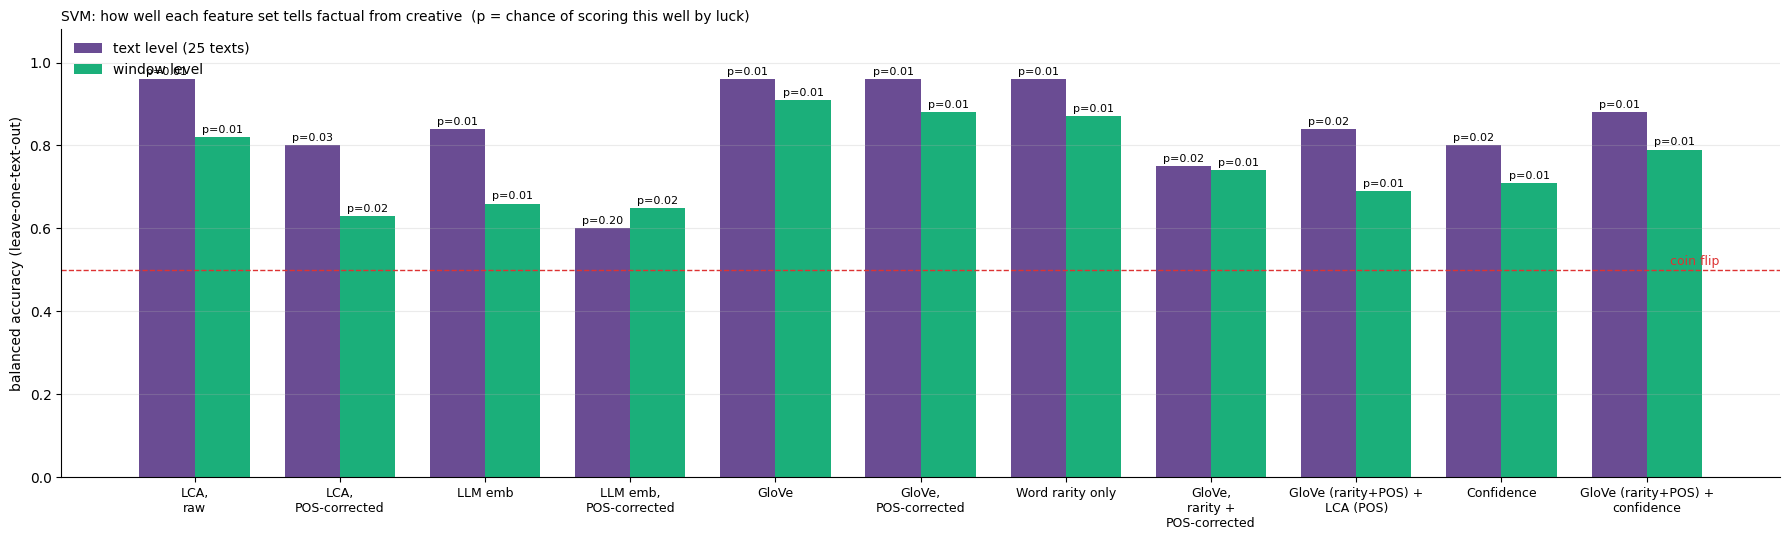

In [10]:
fig, ax = plt.subplots(figsize=(18, 5.5))
names = list(SETS)
x = np.arange(len(names))
for i, (level, color) in enumerate([(f"text level ({N_TEXTS} texts)", "#6a4c93"), ("window level", "#1baf7a")]):
    sub = results[results.level == level].set_index("features").loc[names]
    bars = ax.bar(x + (i - 0.5) * 0.38, sub["balanced_accuracy"], width=0.38, color=color, label=level)
    for b, p in zip(bars, sub["p_value"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"p={p:.2f}" if p >= 0.01 else "p<0.01",
                ha="center", fontsize=8)
ax.axhline(0.5, color="#d33", ls="--", lw=1)
ax.text(len(names) - 0.5, 0.505, "coin flip", color="#d33", ha="right", va="bottom", fontsize=9)
ax.set_xticks(x, [n.replace(" + ", " +" + NL).replace(", ", "," + NL) for n in names], fontsize=9)
ax.set_ylim(0, 1.08)
ax.set_ylabel("balanced accuracy (leave-one-text-out)")
ax.set_title("SVM: how well each feature set tells factual from creative  (p = chance of scoring this well by luck)",
             loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
save(fig, FIG_DIR / "3_svm_accuracy.png")
plt.show()

## 6b. Cross-source test: train on Wikipedia vs Harry Potter, predict Gutenberg
The hardest test of the "Wikipedia vs Harry Potter" problem. The SVM learns **only** from the old sources
(Wikipedia = factual, Harry Potter + jokes = creative), then predicts the 8 Gutenberg texts (4 factual, 4 creative)
it has never seen, from a different site and era.
- If a feature set learned *factual vs creative*, it should still be right here.
- If it only learned *Wikipedia vs Harry Potter* (topic words, style, how familiar the text is to the model),
  it will drop to about 0.5.

With only 8 test texts each one is 12.5%, so read this as a rough check, not a precise score.

,features,8 Gutenberg texts,their windows,texts wrong (whole text)
0,"LCA, raw",0.88,0.78,gut:sherlock
1,"LCA, POS-corrected",0.88,0.64,gut:outline_science
2,LLM emb,0.75,0.58,"gut:candle, gut:outline_science"
3,"LLM emb, POS-corrected",0.62,0.59,"gut:candle, gut:origin_species, gut:outline_sc..."
4,GloVe,1.00,0.86,
5,"GloVe, POS-corrected",1.00,0.85,
6,Word rarity only,0.75,0.76,"gut:oz, gut:outline_science"
7,"GloVe, rarity + POS-corrected",0.88,0.86,gut:oz
8,GloVe (rarity+POS) + LCA (POS),0.88,0.79,gut:oz
9,Confidence,0.38,0.54,"gut:alice, gut:oz, gut:candle, gut:origin_spec..."


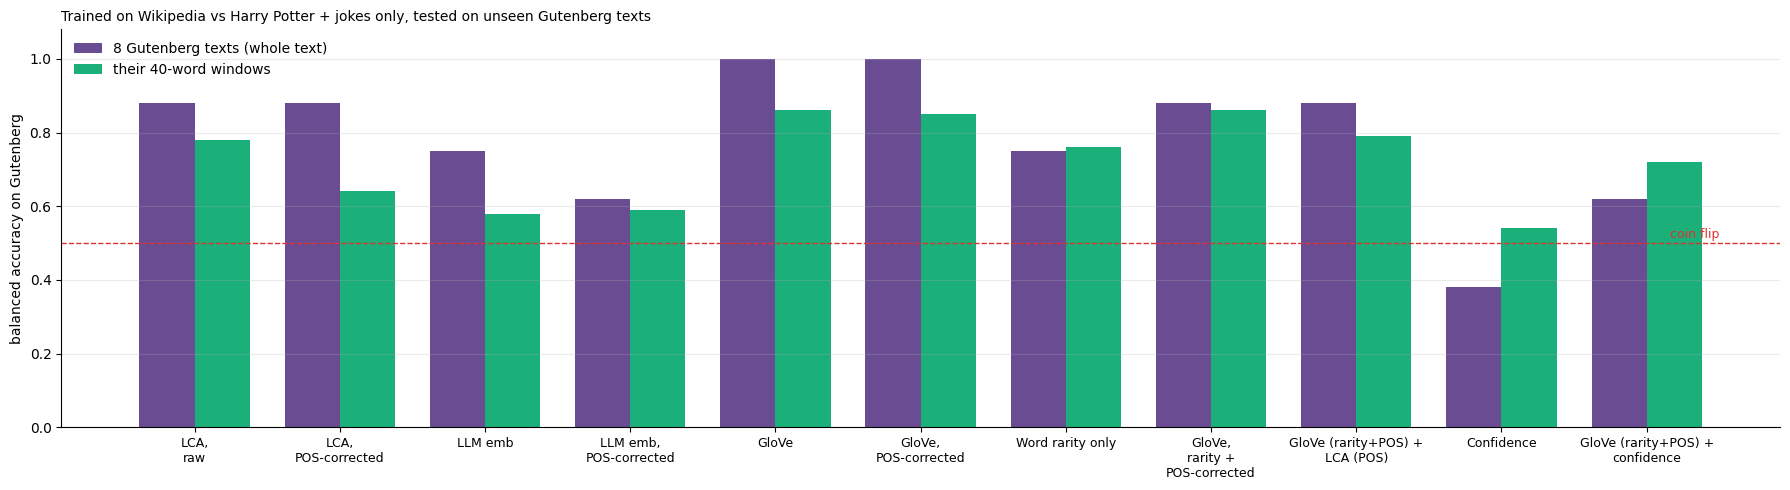

In [11]:
def cross_source(table, feats):
    is_gut = table["text"].str.contains("_gut_").to_numpy()
    train, test = table[~is_gut], table[is_gut]
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced"))
    clf.fit(train[feats], train["kind"])
    pred = clf.predict(test[feats])
    votes = pd.DataFrame({"text": test["text"], "pred": pred}).groupby("text")["pred"].agg(lambda s: s.mode()[0])
    truth = test.groupby("text")["kind"].first()
    return balanced_accuracy_score(test["kind"], pred), [short(t) for t in votes.index if votes[t] != truth[t]]


if DATASET != "extended":
    print("Cross-source test needs DATASET = 'extended'")
else:
    rows = []
    for name, feats in SETS.items():
        acc_t, wrong_t = cross_source(texts, feats)
        acc_w, wrong_w = cross_source(wins, feats)
        rows.append({"features": name, "8 Gutenberg texts": round(acc_t, 2), "their windows": round(acc_w, 2),
                     "texts wrong (whole text)": ", ".join(wrong_t)})
    cross = pd.DataFrame(rows)
    display(cross)

    fig, ax = plt.subplots(figsize=(18, 5))
    x = np.arange(len(cross))
    ax.bar(x - 0.19, cross["8 Gutenberg texts"], width=0.38, color="#6a4c93", label="8 Gutenberg texts (whole text)")
    ax.bar(x + 0.19, cross["their windows"], width=0.38, color="#1baf7a", label="their 40-word windows")
    ax.axhline(0.5, color="#d33", ls="--", lw=1)
    ax.text(len(x) - 0.5, 0.505, "coin flip", color="#d33", ha="right", va="bottom", fontsize=9)
    ax.set_xticks(x, [n.replace(" + ", " +" + NL).replace(", ", "," + NL) for n in cross["features"]], fontsize=9)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("balanced accuracy on Gutenberg")
    ax.set_title("Trained on Wikipedia vs Harry Potter + jokes only, tested on unseen Gutenberg texts",
                 loc="left", fontsize=10)
    ax.legend(frameon=False, loc="upper left")
    ax.grid(axis="y", alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    save(fig, FIG_DIR / "4_cross_source.png")
    plt.show()


## 7. Findings: extended set (25 texts) vs original set (18 texts)

The extended set drops the short Harry Potter opening (261 words) and adds 8 Gutenberg texts: 4 factual (Einstein,
Faraday, Darwin, Thomson) and 4 creative (Alice, Sherlock Holmes, Oz, Grimm). Both new groups come from the same site
and a similar era, so "factual vs creative" is no longer the same as "Wikipedia vs Harry Potter".

**SVM, leave-one-text-out** (balanced accuracy, 0.5 = coin flip)

| features | original, 18 texts | extended, 25 texts | extended, windows | **trained on old sources, tested on Gutenberg** (texts / windows) |
|---|---|---|---|---|
| LCA, raw | 0.84 | 0.96 | 0.82 | 0.88 / 0.78 |
| LCA, POS-corrected | 0.54 (luck) | 0.80 | 0.63 | 0.88 / 0.64 |
| LLM emb, POS-corrected | 0.61 (luck) | 0.60 (luck) | 0.65 | 0.62 / 0.59 |
| Word rarity only | 1.00 | 0.96 | 0.87 | 0.75 / 0.76 |
| **GloVe, rarity + POS-corrected** | 0.65 (luck) | **0.75** | **0.74** | **0.88 / 0.86** |
| GloVe (rarity+POS) + LCA (POS) | 0.72 | 0.84 | 0.69 | 0.88 / 0.79 |
| **Confidence** | **0.95** | 0.80 | 0.71 | **0.38 / 0.54** |

1. **Model confidence was mostly "is this Wikipedia?".** It was the best feature on the original set (0.95), but a
   model trained on Wikipedia vs Harry Potter gets the Gutenberg texts **wrong more often than a coin flip (0.38)**.
   The models are simply more sure on Wikipedia text, probably because Wikipedia is in their training data.
2. **The corrected GloVe metric holds up best.** With rarity and part of speech removed, it now clearly beats luck
   (0.75 texts, 0.74 windows, p ≈ 0.01-0.02), and trained only on the old sources it still gets **7 of 8 Gutenberg texts**
   right (0.88; only Oz wrong) and **0.86 of their windows**. It learned something about factual vs creative,
   not about Wikipedia vs Harry Potter.
3. **Same direction as before** (effect sizes, section 5): creative curves **jump more** (+1.71) and **vary more**
   (+1.09), as the hypothesis predicts, but are **less spread on average** (-1.62), which it doesn't.
4. **POS-corrected LCA improved with more texts** (0.54 → 0.80) and transfers to Gutenberg at text level (0.88),
   but much less at window level (0.64): a weaker, less steady signal than GloVe.
5. **Word rarity still separates the groups** (0.96) and partly transfers (0.75): factual texts use rarer words
   in both sources. That's why GloVe has to be corrected for it.

**Caveats:** 8 Gutenberg test texts is few (each = 12.5%). The rarity correction is a straight-line fit. Gutenberg
creative texts include children's books (Alice, Oz), which differ in style from Harry Potter.
